# Experiment 3: Random Variables and Probability Distributions

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)

## Discrete random variable: expectation and variance from a PMF

Sum of probabilities: 1.0000000000000002
E[X] = 2.0
Var(X) = 1.2 | SD = 1.0954


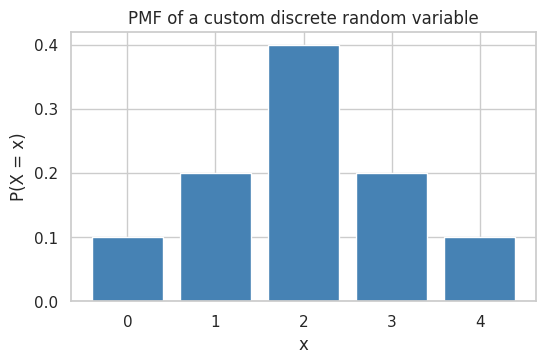

In [2]:
x = np.array([0, 1, 2, 3, 4])
p = np.array([0.1, 0.2, 0.4, 0.2, 0.1])
print("Sum of probabilities:", p.sum())
mean = np.sum(x * p)
var = np.sum((x - mean) ** 2 * p)
print("E[X] =", mean)
print("Var(X) =", round(var, 4), "| SD =", round(np.sqrt(var), 4))

plt.figure(figsize=(6, 3.5))
plt.bar(x, p, color="steelblue")
plt.xlabel("x"); plt.ylabel("P(X = x)"); plt.title("PMF of a custom discrete random variable")
plt.show()

## Bernoulli distribution

Mean, Var: (np.float64(0.6), np.float64(0.24))
Sample mean: 0.613 | Sample var: 0.2372


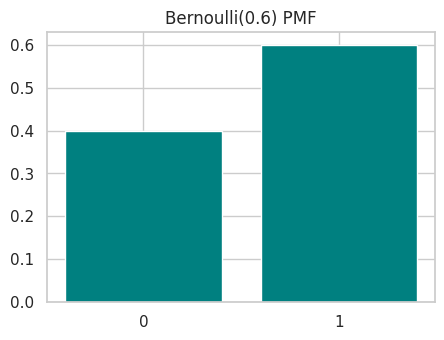

In [3]:
p_b = 0.6
bern = stats.bernoulli(p_b)
print("Mean, Var:", bern.stats(moments="mv"))
sample = bern.rvs(size=1000, random_state=42)
print("Sample mean:", sample.mean(), "| Sample var:", sample.var().round(4))
plt.figure(figsize=(5, 3.5))
plt.bar([0, 1], bern.pmf([0, 1]), color="teal")
plt.xticks([0, 1]); plt.title("Bernoulli(0.6) PMF")
plt.show()

## Binomial distribution

Mean, Var: (np.float64(3.0), np.float64(2.1))
P(X = 3) = 0.2668


P(X <= 3) = 0.6496
P(X >= 4) = 0.3504
P(2 <= X <= 5) = 0.8033


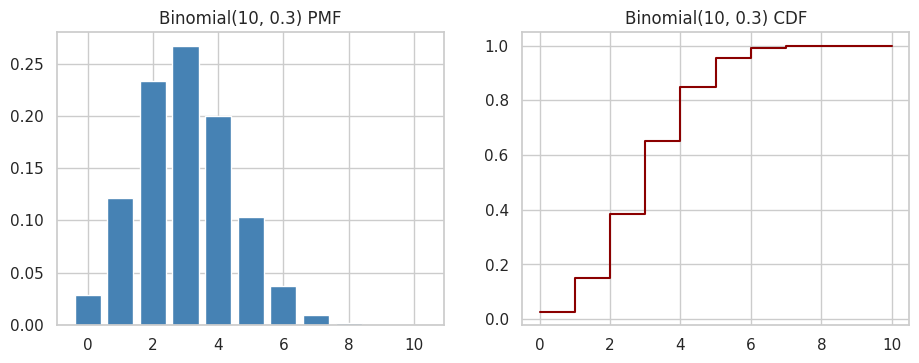

,empirical,theoretical
0,0.0278,0.0282
1,0.1250,0.1211
2,0.2345,0.2335
3,0.2725,0.2668
4,0.1952,0.2001
5,0.1009,0.1029
6,0.0352,0.0368
7,0.0076,0.0090
8,0.0013,0.0014


In [4]:
n, p_bin = 10, 0.3
binom = stats.binom(n, p_bin)
k = np.arange(0, n + 1)
print("Mean, Var:", binom.stats(moments="mv"))
print("P(X = 3) =", round(binom.pmf(3), 4))
print("P(X <= 3) =", round(binom.cdf(3), 4))
print("P(X >= 4) =", round(binom.sf(3), 4))
print("P(2 <= X <= 5) =", round(binom.cdf(5) - binom.cdf(1), 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(k, binom.pmf(k), color="steelblue")
axes[0].set_title("Binomial(10, 0.3) PMF")
axes[1].step(k, binom.cdf(k), where="post", color="darkred")
axes[1].set_title("Binomial(10, 0.3) CDF")
plt.show()

sim = binom.rvs(size=10000, random_state=42)
emp = pd.Series(sim).value_counts(normalize=True).sort_index()
pd.DataFrame({"empirical": emp, "theoretical": binom.pmf(emp.index)}).round(4)

## Poisson distribution

Mean, Var: (np.float64(4.0), np.float64(4.0))
P(X = 2) = 0.1465
P(X > 6) = 0.1107


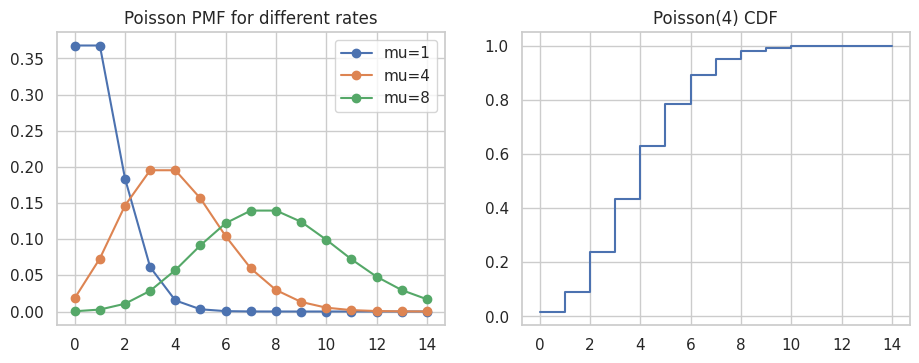

In [5]:
mu = 4
pois = stats.poisson(mu)
k = np.arange(0, 15)
print("Mean, Var:", pois.stats(moments="mv"))
print("P(X = 2) =", round(pois.pmf(2), 4))
print("P(X > 6) =", round(pois.sf(6), 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for m in [1, 4, 8]:
    axes[0].plot(k, stats.poisson(m).pmf(k), marker="o", label=f"mu={m}")
axes[0].set_title("Poisson PMF for different rates"); axes[0].legend()
axes[1].step(k, pois.cdf(k), where="post")
axes[1].set_title("Poisson(4) CDF")
plt.show()

## Geometric distribution

Mean, Var: (np.float64(4.0), np.float64(12.0))
P(first success on trial 3) = 0.1406


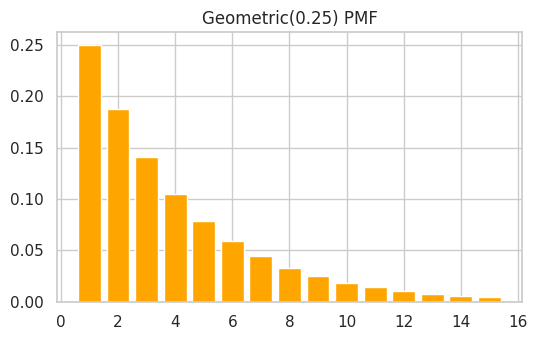

In [6]:
geom = stats.geom(0.25)
k = np.arange(1, 16)
print("Mean, Var:", geom.stats(moments="mv"))
print("P(first success on trial 3) =", round(geom.pmf(3), 4))
plt.figure(figsize=(6, 3.5))
plt.bar(k, geom.pmf(k), color="orange")
plt.title("Geometric(0.25) PMF")
plt.show()

## Uniform distribution

Mean, Var: (np.float64(5.0), np.float64(3.0))
P(3 < X < 5) = 0.3333


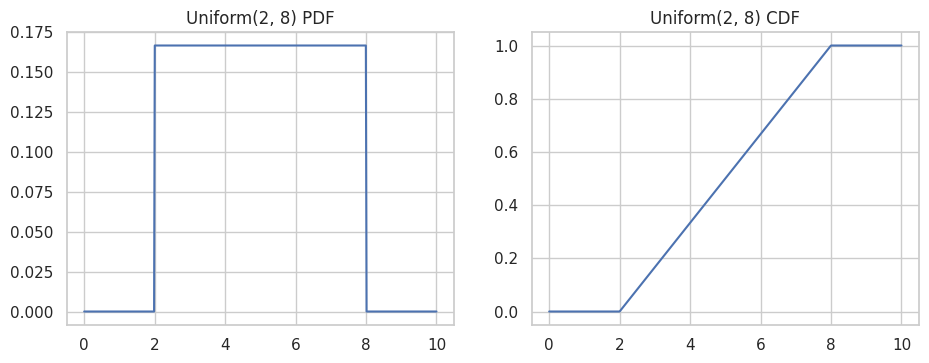

In [7]:
unif = stats.uniform(loc=2, scale=6)  # U(2, 8)
xs = np.linspace(0, 10, 500)
print("Mean, Var:", unif.stats(moments="mv"))
print("P(3 < X < 5) =", round(unif.cdf(5) - unif.cdf(3), 4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(xs, unif.pdf(xs)); axes[0].set_title("Uniform(2, 8) PDF")
axes[1].plot(xs, unif.cdf(xs)); axes[1].set_title("Uniform(2, 8) CDF")
plt.show()

## Normal distribution

P(X < 60) = 0.8413
P(40 < X < 65) = 0.7745
P(X > 70) = 0.0228
90th percentile = 62.816
Z-score of 65 = 1.5


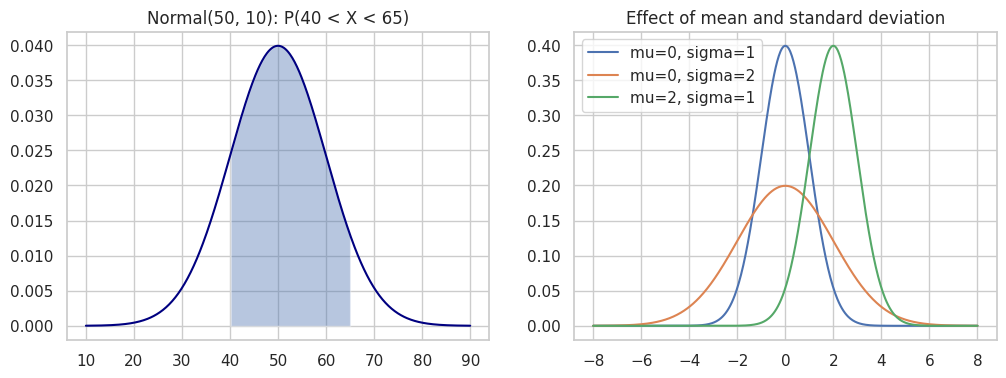

P(within 1 SD) = 0.6827
P(within 2 SD) = 0.9545
P(within 3 SD) = 0.9973


In [8]:
mu, sigma = 50, 10
norm = stats.norm(mu, sigma)
xs = np.linspace(10, 90, 500)
print("P(X < 60) =", round(norm.cdf(60), 4))
print("P(40 < X < 65) =", round(norm.cdf(65) - norm.cdf(40), 4))
print("P(X > 70) =", round(norm.sf(70), 4))
print("90th percentile =", round(norm.ppf(0.90), 3))
print("Z-score of 65 =", (65 - mu) / sigma)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(xs, norm.pdf(xs), color="navy")
axes[0].fill_between(xs, norm.pdf(xs), where=(xs >= 40) & (xs <= 65), alpha=0.4)
axes[0].set_title("Normal(50, 10): P(40 < X < 65)")
for m, s in [(0, 1), (0, 2), (2, 1)]:
    z = np.linspace(-8, 8, 500)
    axes[1].plot(z, stats.norm(m, s).pdf(z), label=f"mu={m}, sigma={s}")
axes[1].legend(); axes[1].set_title("Effect of mean and standard deviation")
plt.show()

for k_sd in [1, 2, 3]:
    prob = stats.norm.cdf(k_sd) - stats.norm.cdf(-k_sd)
    print(f"P(within {k_sd} SD) = {prob:.4f}")

## Exponential distribution

Mean, Var: (np.float64(2.0), np.float64(4.0))
P(X > 3) = 0.2231
Median = 1.3863


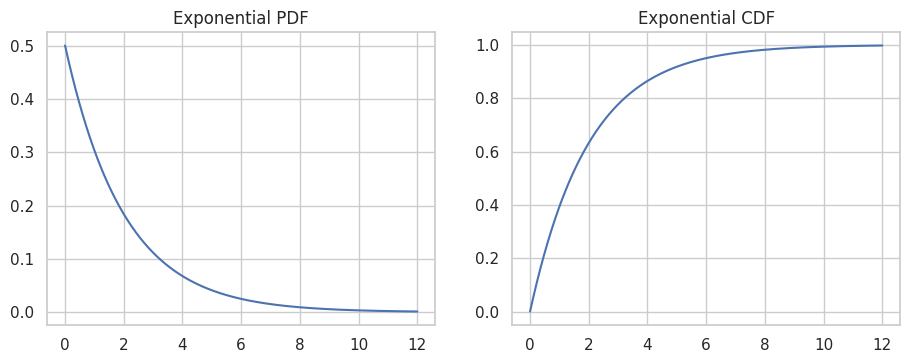

In [9]:
expo = stats.expon(scale=2)  # mean = 2
xs = np.linspace(0, 12, 500)
print("Mean, Var:", expo.stats(moments="mv"))
print("P(X > 3) =", round(expo.sf(3), 4))
print("Median =", round(expo.median(), 4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(xs, expo.pdf(xs)); axes[0].set_title("Exponential PDF")
axes[1].plot(xs, expo.cdf(xs)); axes[1].set_title("Exponential CDF")
plt.show()

## Student t and Chi-square distributions

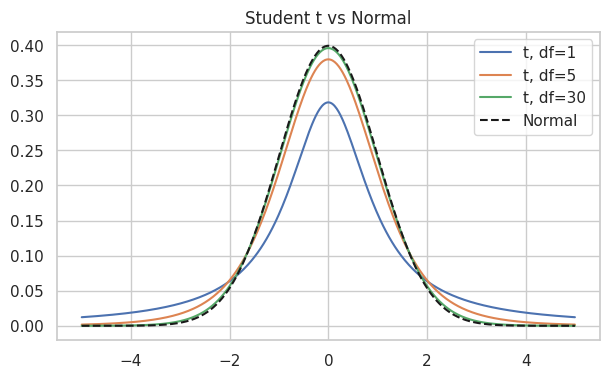

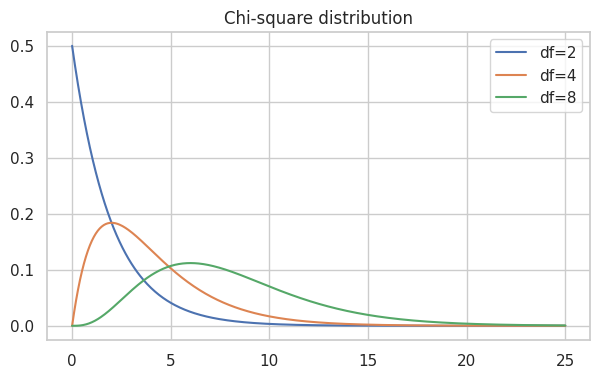

In [10]:
xs = np.linspace(-5, 5, 500)
plt.figure(figsize=(7, 4))
for df_ in [1, 5, 30]:
    plt.plot(xs, stats.t(df_).pdf(xs), label=f"t, df={df_}")
plt.plot(xs, stats.norm.pdf(xs), "k--", label="Normal")
plt.legend(); plt.title("Student t vs Normal")
plt.show()

xs = np.linspace(0, 25, 500)
plt.figure(figsize=(7, 4))
for df_ in [2, 4, 8]:
    plt.plot(xs, stats.chi2(df_).pdf(xs), label=f"df={df_}")
plt.legend(); plt.title("Chi-square distribution")
plt.show()

## Sampling: empirical vs theoretical distributions

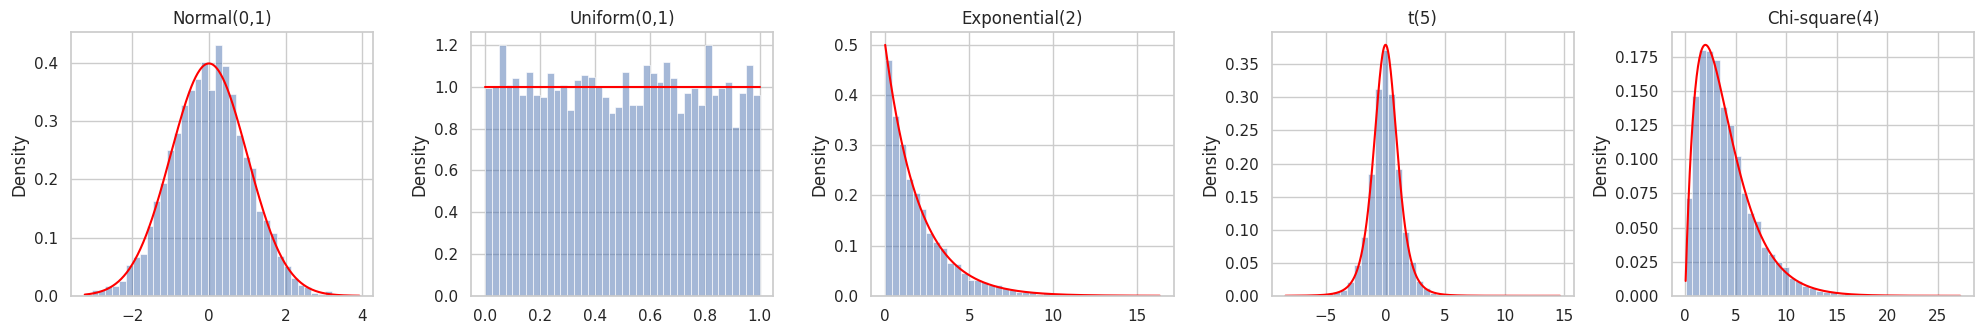

,distribution,theoretical mean,sample mean,theoretical var,sample var
0,"Normal(0,1)",0.0,0.0010,1.0000,1.0018
1,"Uniform(0,1)",0.5,0.4995,0.0833,0.0831
2,Exponential(2),2.0,1.9919,4.0000,3.9440
3,t(5),0.0,-0.0075,1.6667,1.6741
4,Chi-square(4),4.0,4.0068,8.0000,8.0172


In [11]:
dists = {
    "Normal(0,1)": stats.norm(0, 1),
    "Uniform(0,1)": stats.uniform(0, 1),
    "Exponential(2)": stats.expon(scale=2),
    "t(5)": stats.t(5),
    "Chi-square(4)": stats.chi2(4),
}
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, (name, d) in zip(axes, dists.items()):
    s = d.rvs(size=5000, random_state=42)
    sns.histplot(s, stat="density", bins=40, ax=ax, alpha=0.5)
    xs = np.linspace(s.min(), s.max(), 400)
    ax.plot(xs, d.pdf(xs), color="red")
    ax.set_title(name)
plt.tight_layout()
plt.show()

rows = []
for name, d in dists.items():
    s = d.rvs(size=100000, random_state=42)
    tm, tv = d.stats(moments="mv")
    rows.append([name, float(tm), s.mean(), float(tv), s.var()])
pd.DataFrame(rows, columns=["distribution", "theoretical mean", "sample mean", "theoretical var", "sample var"]).round(4)

## Law of large numbers

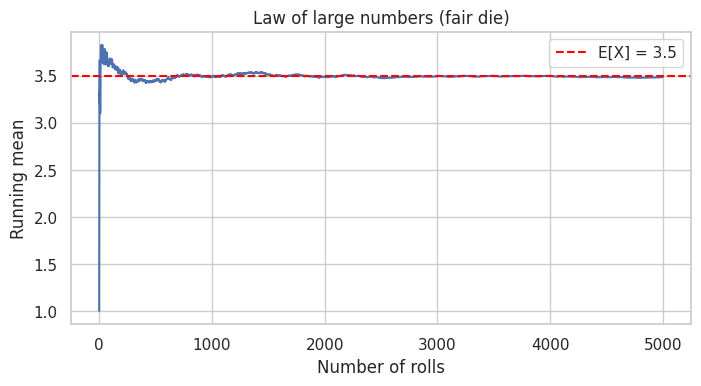

In [12]:
rolls = rng.integers(1, 7, size=5000)
running_mean = np.cumsum(rolls) / np.arange(1, len(rolls) + 1)
plt.figure(figsize=(8, 3.8))
plt.plot(running_mean)
plt.axhline(3.5, color="red", linestyle="--", label="E[X] = 3.5")
plt.xlabel("Number of rolls"); plt.ylabel("Running mean"); plt.legend()
plt.title("Law of large numbers (fair die)")
plt.show()

## Central limit theorem

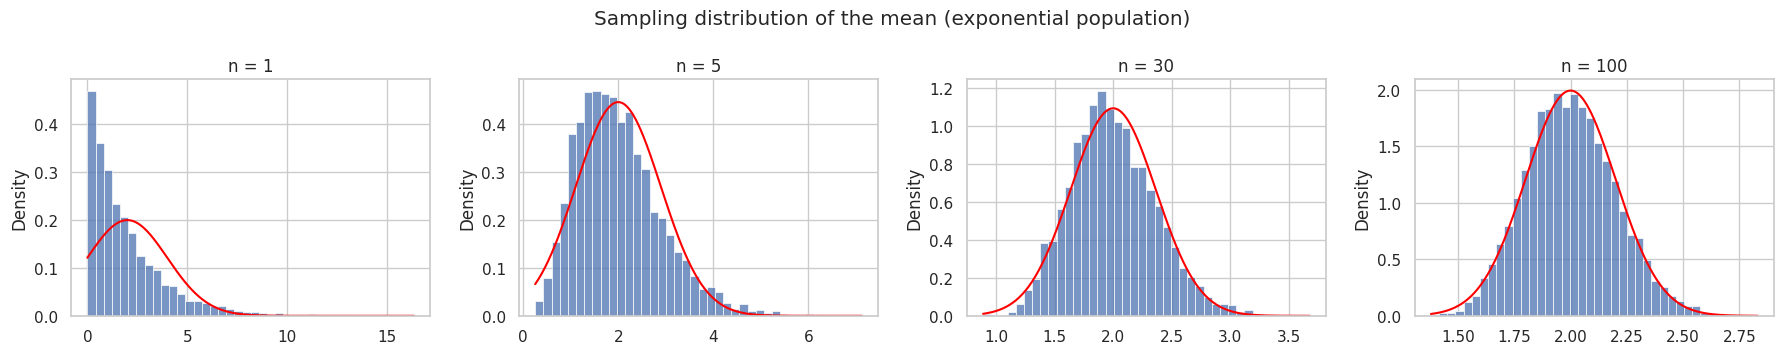

In [13]:
pop = stats.expon(scale=2)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, n in zip(axes, [1, 5, 30, 100]):
    means = pop.rvs(size=(5000, n), random_state=42).mean(axis=1)
    sns.histplot(means, stat="density", bins=40, ax=ax)
    xs = np.linspace(means.min(), means.max(), 300)
    ax.plot(xs, stats.norm(2, 2 / np.sqrt(n)).pdf(xs), color="red")
    ax.set_title(f"n = {n}")
plt.suptitle("Sampling distribution of the mean (exponential population)")
plt.tight_layout()
plt.show()

## Normality check

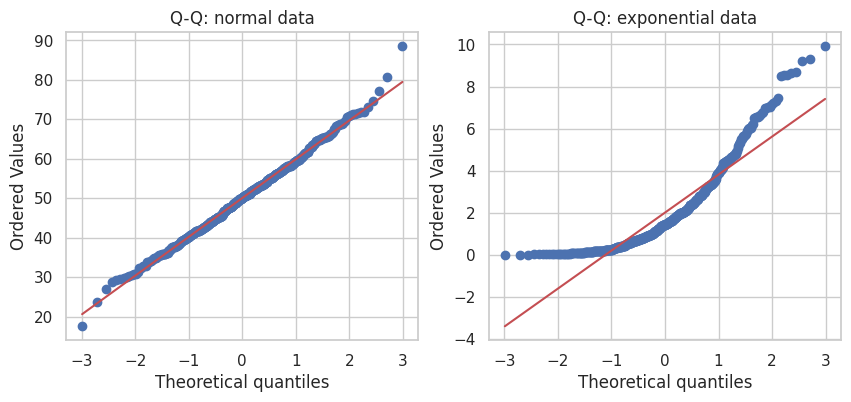

Shapiro (normal sample): ShapiroResult(statistic=np.float64(0.9967013775391397), pvalue=np.float64(0.40126905399330937))
Shapiro (exponential sample): ShapiroResult(statistic=np.float64(0.8508717526761671), pvalue=np.float64(2.4377983226252295e-21))


In [14]:
sample_n = stats.norm(50, 10).rvs(size=500, random_state=42)
sample_e = stats.expon(scale=2).rvs(size=500, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(sample_n, dist="norm", plot=axes[0]); axes[0].set_title("Q-Q: normal data")
stats.probplot(sample_e, dist="norm", plot=axes[1]); axes[1].set_title("Q-Q: exponential data")
plt.show()
print("Shapiro (normal sample):", stats.shapiro(sample_n))
print("Shapiro (exponential sample):", stats.shapiro(sample_e))